<a href="https://colab.research.google.com/github/JUAN-VILLOTA/har-smartphones-ml-grupo11/blob/main/02_modelos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Human Activity Recognition Using Smartphones — Grupo 11
## Parte 2. Entrenamiento y evaluación de modelos

**Integrantes:** Juan David Villota Córdoba y Sammir Alejandro Bolaños Luna  
**Curso:** Introducción al Aprendizaje Automático — Universidad de Antioquia, 2026-2

**Qué hace este notebook:** define la metodología de validación por voluntario, entrena los cinco modelos que pide la guía, ajusta sus hiperparámetros, reporta los resultados con intervalos de confianza y evalúa una sola vez en la partición oficial de prueba.

**Cómo ejecutarlo:** abrirlo en Colab y usar *Entorno de ejecución → Ejecutar todo*. Descarga los datos directamente de UCI.

> Las celdas marcadas con **TU TURNO** tienen espacios `___` para completar.

## 1. Preparar las herramientas

In [47]:
import io
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

## 2. Cargar los datos

Es la misma carga del notebook 01 (descarga en memoria, nombres únicos y partición oficial). Se repite aquí para que este notebook funcione solo, sin depender del anterior.

In [48]:
URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
with urllib.request.urlopen(URL) as respuesta:
    z = zipfile.ZipFile(io.BytesIO(respuesta.read()))
internos = [n for n in z.namelist() if n.endswith(".zip")]
if internos:
    z = zipfile.ZipFile(io.BytesIO(z.read(internos[0])))

def leer(sufijo, **kw):
    """Carga el archivo cuya ruta termina en `sufijo` (sin encabezados, separado por espacios)."""
    ruta = [n for n in z.namelist() if n.endswith(sufijo) and "Inertial" not in n][0]
    return pd.read_csv(z.open(ruta), sep=r"\s+", header=None, **kw)

features = leer("features.txt")[1].tolist()
etiquetas = leer("activity_labels.txt").set_index(0)[1].to_dict()

# Nombres únicos: sufijo solo a las repeticiones
vistos, nombres = {}, []
for nombre in features:
    vistos[nombre] = vistos.get(nombre, 0) + 1
    nombres.append(nombre if vistos[nombre] == 1 else f"{nombre}_{vistos[nombre]}")

partes = {}
for conjunto in ["train", "test"]:
    X = leer(f"X_{conjunto}.txt")
    X.columns = nombres
    X["actividad"] = leer(f"y_{conjunto}.txt")[0].map(etiquetas)
    X["sujeto"] = leer(f"subject_{conjunto}.txt")[0]
    partes[conjunto] = X

print("Entrenamiento:", partes["train"].shape, "| Prueba:", partes["test"].shape)

Entrenamiento: (7352, 563) | Prueba: (2947, 563)


## 3. Separar entradas, salida y grupos

- `X`: las 561 características. Es lo único que ve el modelo.
- `y`: la actividad que queremos predecir.
- `g`: el voluntario de cada ventana. **No entra al modelo**; solo le dice a la validación quién es quién, para no mezclar ventanas de la misma persona entre entrenamiento y validación.

La partición de prueba (`partes["test"]`) no se toca hasta el final.

La columna `sujeto` dice a qué voluntario pertenece cada ventana.

In [49]:
X = partes["train"][nombres]
y = partes["train"]["actividad"]
g = partes["train"]["sujeto"]

print("X:", X.shape, "| y:", y.shape, "| voluntarios:", g.nunique())

X: (7352, 561) | y: (7352,) | voluntarios: 21


## 4. Metodología de validación: ¿al azar o por voluntario?

Comparamos dos formas de hacer validación cruzada de 5 particiones con el mismo modelo sencillo (estandarización + regresión logística):

- **KFold al azar:** reparte las ventanas sin mirar de quién son.
- **GroupKFold por voluntario:** todas las ventanas de una persona quedan juntas, en entrenamiento o en validación, nunca en ambos.

El `StandardScaler` va dentro de un `Pipeline` (`make_pipeline`), así que en cada partición se ajusta solo con los datos de entrenamiento de esa partición. Así se evita la fuga de información por el preprocesamiento.

La métrica es el F1 macro, que pesa igual las seis actividades.

**Predicción antes de ejecutar:** la validación al azar (KFold) debería dar un F1 macro más alto que la validación por voluntario (GroupKFold). Con KFold, ventanas de la misma persona, e incluso ventanas consecutivas que comparten el 50 % de sus lecturas, quedan a la vez en entrenamiento y en validación, así que el modelo se evalúa con casi copias de lo que vio. Con GroupKFold, cada partición de validación tiene solo personas nuevas para el modelo.

El primer paso del Pipeline estandariza las características; `groups=g` le dice a GroupKFold quién es quién. Sin ese argumento no podría agrupar por voluntario.

In [50]:
modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

cv_azar = KFold(n_splits=5, shuffle=True, random_state=0)
cv_grupos = GroupKFold(n_splits=5)

s_azar = cross_val_score(modelo, X, y, cv=cv_azar, scoring="f1_macro")
s_grupos = cross_val_score(modelo, X, y, cv=cv_grupos, groups=g, scoring="f1_macro")

print(f"KFold al azar:        {s_azar.mean():.4f} ± {s_azar.std():.4f}")
print(f"GroupKFold voluntario: {s_grupos.mean():.4f} ± {s_grupos.std():.4f}")

KFold al azar:        0.9841 ± 0.0034
GroupKFold voluntario: 0.9331 ± 0.0425


**Interpretación** *(completar después de ejecutar, con los números obtenidos)*:

- ¿Se cumplió la predicción? KFold: ___ ; GroupKFold: ___ ; diferencia: ___ puntos.
- La diferencia es el optimismo que produce la fuga de información entre ventanas de un mismo voluntario.
- ¿Cuál desviación estándar es mayor? Con GroupKFold suele variar más entre particiones, porque cada una tiene personas distintas y unas son más difíciles que otras.
- Conclusión: en el resto del proyecto, los hiperparámetros se ajustan con GroupKFold por voluntario.

## 5. Configuración experimental común

Todos los modelos se evalúan con las mismas reglas, para que la comparación sea justa:

- **Validación:** `GroupKFold` de 5 particiones por voluntario dentro de las 7 352 ventanas de entrenamiento (21 voluntarios, unos 4 por partición). Como `GroupKFold` no baraja, **todas las búsquedas usan exactamente las mismas particiones**.
- **Búsqueda de hiperparámetros:** `GridSearchCV`, como en la clase 06 del curso, probando todas las combinaciones de una malla.
- **Preprocesamiento:** `StandardScaler` dentro de un `Pipeline`, ajustado solo con la parte de entrenamiento de cada partición.
- **Métrica para elegir:** F1 macro, que pesa igual las seis actividades. También se registra la exactitud, que es la que reportan los artículos del estado del arte, para poder compararnos.
- **Intervalos:** cada resultado de validación se reporta como **media ± 2·desviación estándar** de las 5 particiones, la misma forma que usa el profesor en la clase 06. Con 5 particiones, este intervalo es aproximado.
- **Sin sobremuestreo:** las clases van de 13,7 % a 18,9 % (relación 1,4 a 1, ver notebook 01), un desbalance leve que no lo justifica.
- **Prueba:** la partición oficial de prueba (9 voluntarios) se usa una sola vez, en la sección 13, con las configuraciones ya elegidas.

**Tiempo de ejecución:** las búsquedas completas pueden tardar entre 30 y 60 minutos en Colab. La SVM y la red neuronal son las más lentas.

In [51]:
import time
import warnings

from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

orden = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]
nombres_es = {"WALKING": "Caminar", "WALKING_UPSTAIRS": "Subir escaleras",
              "WALKING_DOWNSTAIRS": "Bajar escaleras", "SITTING": "Sentado",
              "STANDING": "De pie", "LAYING": "Acostado"}

CV = GroupKFold(n_splits=5)
METRICAS = {"f1": "f1_macro", "acc": "accuracy"}
busquedas = {}   # aquí se guarda la búsqueda de cada modelo

Tres funciones de apoyo para no repetir código:

- `buscar`: ejecuta la búsqueda en malla con validación por voluntario y la guarda en `busquedas`.
- `tabla`: convierte los resultados de una búsqueda en una tabla legible, una fila por combinación de hiperparámetros.
- `graficar`: dibuja el F1 macro de validación (línea continua, con barras de ±2·desv. est.) y de entrenamiento (línea punteada) contra un hiperparámetro. La distancia entre las dos líneas muestra el sobreajuste.

In [52]:
def buscar(nombre, pipeline, malla):
    """Búsqueda en malla con GroupKFold por voluntario; elige por F1 macro."""
    gs = GridSearchCV(pipeline, malla, cv=CV, scoring=METRICAS, refit="f1",
                      return_train_score=True, n_jobs=-1)
    inicio = time.time()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")   # avisos de convergencia; se revisan en los resultados
        gs.fit(X, y, groups=g)
    busquedas[nombre] = gs
    i = gs.best_index_
    r = gs.cv_results_
    print(f"{nombre}: {len(r['params'])} combinaciones en {time.time() - inicio:.0f} s")
    print("Mejores hiperparámetros:", {k.replace('modelo__', ''): v for k, v in gs.best_params_.items()})
    print(f"F1 macro validación: {r['mean_test_f1'][i]:.4f} ± {2 * r['std_test_f1'][i]:.4f}")
    return gs


def tabla(gs):
    """Una fila por combinación: hiperparámetros, F1 y exactitud (media y 2·desv. est.)."""
    r = pd.DataFrame(gs.cv_results_)
    params = pd.DataFrame(list(r["params"])).rename(columns=lambda c: c.replace("modelo__", ""))
    out = params.assign(
        f1_val=r["mean_test_f1"], f1_val_2std=2 * r["std_test_f1"],
        f1_ent=r["mean_train_f1"], f1_ent_2std=2 * r["std_train_f1"],
        acc_val=r["mean_test_acc"], acc_val_2std=2 * r["std_test_acc"],
        seg_ajuste=r["mean_fit_time"], ranking=r["rank_test_f1"])
    return out.sort_values("ranking").reset_index(drop=True)


def graficar(df, x, serie=None, titulo="", etiqueta_x=None, log_x=False, ax=None):
    """F1 macro de validación (±2·std) y de entrenamiento contra el hiperparámetro x."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))
    grupos = df.groupby(serie) if serie else [(None, df)]
    for valor, d in grupos:
        d = d.sort_values(x)
        etiqueta = f"{serie} = {valor}" if serie else "validación"
        linea = ax.errorbar(d[x], d["f1_val"], yerr=d["f1_val_2std"], marker="o", capsize=3, label=etiqueta)
        ax.plot(d[x], d["f1_ent"], linestyle="--", color=linea[0].get_color(), alpha=0.6)
    if log_x:
        ax.set_xscale("log")
    ax.set_xlabel(etiqueta_x or x)
    ax.set_ylabel("F1 macro")
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
    ax.legend(title="continua: validación; punteada: entrenamiento", fontsize=8, title_fontsize=8)
    return ax

## 6. Modelo de referencia

**Qué es:** un clasificador "tonto" (`DummyClassifier`) que siempre responde la actividad más frecuente del entrenamiento, sin mirar las características.

**Por qué:** da el piso. Cualquier modelo útil debe superarlo con amplio margen. Con seis clases casi balanceadas, su exactitud debería rondar el 18 % y su F1 macro ser muy bajo, porque acierta una sola clase.

In [53]:
referencia = Pipeline([("modelo", DummyClassifier(strategy="most_frequent"))])
buscar("Referencia", referencia, {"modelo__strategy": ["most_frequent"]});

Referencia: 1 combinaciones en 0 s
Mejores hiperparámetros: {'strategy': 'most_frequent'}
F1 macro validación: 0.0535 ± 0.0049


## 7. Modelo paramétrico: análisis discriminante lineal (LDA)

**Qué es:** supone que las ventanas de cada actividad siguen una distribución gaussiana con su propia media, y que todas las actividades comparten la misma matriz de covarianza. Clasifica cada ventana en la actividad cuya gaussiana le da mayor probabilidad. Al compartir la covarianza, las fronteras entre actividades son lineales. Es paramétrico porque queda descrito por un número fijo de parámetros (6 medias y una covarianza), sin importar cuántas ventanas haya (clase 03).

**Cómo se eligió.** [Guía] El modelo paramétrico puede basarse en funciones discriminantes gaussianas o en regresión logística. En lugar de suponer cuál funcionaría mejor, se compararon todas con la misma validación por voluntario (celda siguiente):

- **Bayes ingenuo (`GaussianNB`):** supone que las 561 características son independientes, y son muy redundantes.
- **QDA:** estima una covarianza de 561 × 561 por clase con solo 986 a 1 407 ventanas por clase; queda singular y necesita regularización para poder entrenarse.
- **Regresión logística:** modela solo la frontera entre clases. [Fuente] Xu et al. (2019) reportan 95,89 % con regresión softmax.
- **LDA:** al compartir una sola covarianza entre las seis clases, la estima con todas las ventanas de entrenamiento, por lo que es más estable que QDA.

Se elige el que obtenga el mayor F1 macro en validación. La decisión se toma solo con validación, antes de mirar la partición de prueba.

In [54]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for nombre, modelo in [("GaussianNB", GaussianNB()),
                           ("QDA", QuadraticDiscriminantAnalysis()),
                           ("QDA regularizado", QuadraticDiscriminantAnalysis(reg_param=0.1)),
                           ("Reg. logística", LogisticRegression(max_iter=3000)),
                           ("LDA", LinearDiscriminantAnalysis())]:
        pipe = Pipeline([("escalar", StandardScaler()), ("modelo", modelo)])
        try:
            s = cross_validate(pipe, X, y, cv=CV, groups=g, scoring=METRICAS, n_jobs=-1)
            print(f"{nombre:<17} F1 macro validación: {s['test_f1'].mean():.4f} ± {2 * s['test_f1'].std():.4f}")
        except ValueError as e:
            # Algunas versiones de scikit-learn detienen QDA si la covarianza de una clase es singular
            print(f"{nombre:<17} no se pudo entrenar: {str(e).strip().splitlines()[-1][:150]}")

GaussianNB        F1 macro validación: 0.6717 ± 0.1553
QDA               no se pudo entrenar: numpy.linalg.LinAlgError: The covariance matrix of class LAYING is not full rank. Increase the value of `reg_param` to reduce the collinearity.
QDA regularizado  F1 macro validación: 0.8855 ± 0.1073
Reg. logística    F1 macro validación: 0.9328 ± 0.0852
LDA               F1 macro validación: 0.9505 ± 0.0578


**Hiperparámetro y malla:**

| Hiperparámetro | Qué controla | Malla |
| --- | --- | --- |
| `shrinkage` | Regularización de la covarianza: la mezcla con una matriz diagonal. 0 = covarianza estimada tal cual; 1 = solo la diagonal (variables tratadas como independientes) | 0,0001; 0,001; 0,01; 0,1; 0,3; 0,6; 0,9 |

Se usa `solver="lsqr"`, que es el que admite `shrinkage` en scikit-learn. La malla es casi logarítmica porque los valores pequeños ya cambian el resultado.

In [55]:
lda = Pipeline([("escalar", StandardScaler()),
                ("modelo", LinearDiscriminantAnalysis(solver="lsqr"))])
malla_lda = {"modelo__shrinkage": [0.0001, 0.001, 0.01, 0.1, 0.3, 0.6, 0.9]}

busquedas.pop("Regresión logística", None)   # por si quedó de una ejecución anterior
buscar("LDA", lda, malla_lda)
tabla_lda = tabla(busquedas["LDA"])
tabla_lda

LDA: 7 combinaciones en 6 s
Mejores hiperparámetros: {'shrinkage': 0.0001}
F1 macro validación: 0.9502 ± 0.0591


,shrinkage,f1_val,f1_val_2std,f1_ent,f1_ent_2std,acc_val,acc_val_2std,seg_ajuste,ranking
0,0.0001,0.950178,0.059053,0.989160,0.005073,0.949862,0.057294,1.339547,1
1,0.0010,0.948262,0.062480,0.988257,0.005876,0.948260,0.059555,1.448117,2
2,0.0100,0.944581,0.064814,0.986567,0.005517,0.944270,0.062406,1.627189,3
3,0.1000,0.935400,0.078229,0.980268,0.007370,0.935305,0.074636,1.450161,4
4,0.3000,0.927697,0.086839,0.971105,0.009521,0.928193,0.082778,1.185503,5
5,0.6000,0.915599,0.098956,0.955249,0.013159,0.916657,0.092096,1.109488,6
6,0.9000,0.887051,0.100792,0.918362,0.015713,0.889064,0.091340,1.025644,7


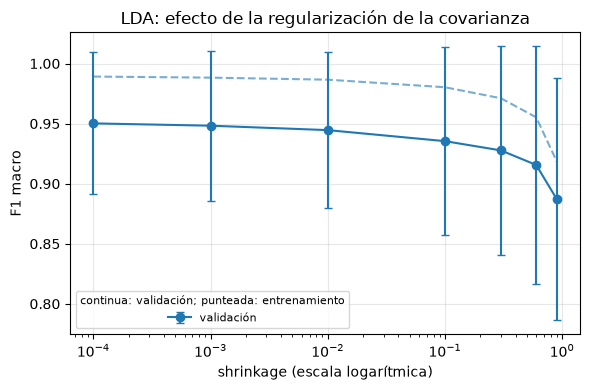

In [56]:
graficar(tabla_lda, "shrinkage", titulo="LDA: efecto de la regularización de la covarianza",
         etiqueta_x="shrinkage (escala logarítmica)", log_x=True)
plt.tight_layout(); plt.savefig("fig_lda.png", dpi=200); plt.show()

## 8. Modelo no paramétrico: k vecinos más cercanos (KNN)

**Qué es:** para clasificar una ventana nueva, busca las *k* ventanas de entrenamiento más parecidas y vota. No aprende pesos: guarda todos los datos. Es no paramétrico porque no supone una forma para la distribución de los datos (clase 04).

**Por qué este y no la ventana de Parzen** [Interpretación]: los dos se vieron en la clase 04. KNN está implementado en scikit-learn como clasificador, tiene hiperparámetros fáciles de interpretar y es el que se practicó en el laboratorio 2. Parzen necesitaría implementarse a mano y su ancho de ventana es más difícil de ajustar en 561 dimensiones.

**Qué esperar:** aquí es donde la validación por voluntario más importa. Con validación al azar, k = 1 parecería excelente, porque el vecino más cercano sería la ventana gemela de la misma persona.

| Hiperparámetro | Qué controla | Malla |
| --- | --- | --- |
| `n_neighbors` (k) | Cuántos vecinos votan: k pequeño sigue el ruido; k grande suaviza la frontera | 1, 3, 5, 7, 11, 15, 25, 35 |
| `p` | Distancia: 1 = Manhattan, 2 = euclidiana | 1, 2 |

In [57]:
knn = Pipeline([("escalar", StandardScaler()), ("modelo", KNeighborsClassifier())])
malla_knn = {"modelo__n_neighbors": [1, 3, 5, 7, 11, 15, 25, 35], "modelo__p": [1, 2]}

buscar("KNN", knn, malla_knn)
tabla_knn = tabla(busquedas["KNN"])
tabla_knn

KNN: 16 combinaciones en 194 s
Mejores hiperparámetros: {'n_neighbors': 25, 'p': 1}
F1 macro validación: 0.8924 ± 0.0589


,n_neighbors,p,f1_val,f1_val_2std,f1_ent,f1_ent_2std,acc_val,acc_val_2std,seg_ajuste,ranking
0,25,1,0.892426,0.058866,0.972051,0.003669,0.895268,0.053437,0.349668,1
1,35,1,0.891229,0.064405,0.964774,0.003310,0.893749,0.059485,0.328090,2
2,15,1,0.890748,0.057081,0.979724,0.003223,0.893539,0.052277,0.399832,3
3,11,1,0.888392,0.063843,0.982639,0.003333,0.891642,0.057327,0.280743,4
4,7,1,0.882559,0.059549,0.988210,0.001452,0.885599,0.053930,0.297218,5
5,5,1,0.882195,0.052684,0.991798,0.001108,0.885652,0.047768,0.279782,6
6,3,1,0.875874,0.048649,0.996764,0.001441,0.879480,0.044516,0.444052,7
7,35,2,0.874600,0.066097,0.953091,0.002988,0.877603,0.060201,0.268375,8
8,11,2,0.871631,0.054694,0.973906,0.002663,0.873961,0.049941,0.375250,9
9,25,2,0.871507,0.068832,0.958979,0.002993,0.874212,0.062308,0.330096,10


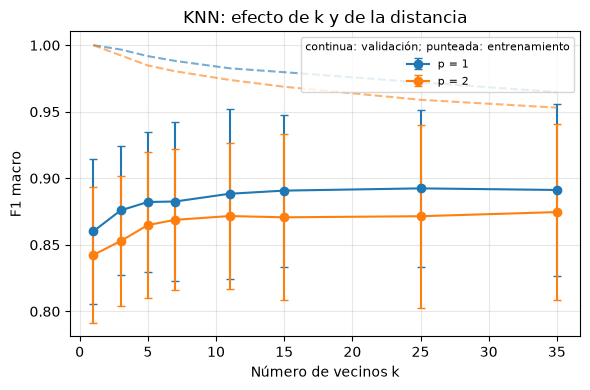

In [58]:
graficar(tabla_knn, "n_neighbors", serie="p", titulo="KNN: efecto de k y de la distancia", etiqueta_x="Número de vecinos k")
plt.tight_layout(); plt.savefig("fig_knn.png", dpi=200); plt.show()

## 9. Ensamble de árboles: Random Forest

**Qué es:** muchos árboles de decisión, cada uno entrenado con una muestra distinta de las ventanas y mirando en cada corte solo un subconjunto al azar de las características. La predicción es el voto de todos los árboles. Combinar árboles distintos reduce la varianza de un árbol solo (clase 10).

**Por qué Random Forest y no Gradient Boosting** [Interpretación]:

- Los árboles de un Random Forest son independientes y se entrenan en paralelo. En Gradient Boosting son secuenciales y, con seis clases, se entrena un árbol por clase en cada iteración, lo que lo hace mucho más lento con 561 características.
- Random Forest es poco sensible a sus hiperparámetros y no necesita estandarización.
- [Fuente] En Xu et al. (2019), Random Forest es uno de los clasificadores base del ensamble.

No lleva `StandardScaler`: los cortes de un árbol solo comparan valores, así que cambiar la escala no altera nada.

| Hiperparámetro | Qué controla | Malla |
| --- | --- | --- |
| `n_estimators` | Número de árboles: más árboles, voto más estable y más tiempo | 10, 50, 100, 200 |
| `max_features` | Características que se miran en cada corte: pocas hacen árboles más distintos entre sí | 5, 20, 40 |

La malla sigue la del laboratorio 3 del curso; `min_samples_leaf` se fija en 3, como allí.

In [59]:
bosque = Pipeline([("modelo", RandomForestClassifier(min_samples_leaf=3, random_state=0))])
malla_rf = {"modelo__n_estimators": [10, 50, 100, 200], "modelo__max_features": [5, 20, 40]}

buscar("Random Forest", bosque, malla_rf)
tabla_rf = tabla(busquedas["Random Forest"])
tabla_rf

Random Forest: 12 combinaciones en 96 s
Mejores hiperparámetros: {'max_features': 5, 'n_estimators': 200}
F1 macro validación: 0.9223 ± 0.0869


,max_features,n_estimators,f1_val,f1_val_2std,f1_ent,f1_ent_2std,acc_val,acc_val_2std,seg_ajuste,ranking
0,5,200,0.922338,0.086900,0.999741,0.000374,0.924866,0.079705,9.672986,1
1,5,100,0.921785,0.079832,0.999745,0.000374,0.924868,0.072765,5.148245,2
2,5,50,0.918629,0.081667,0.999600,0.000273,0.921286,0.074956,2.469116,3
3,20,200,0.918274,0.090824,0.999969,0.000124,0.919255,0.087944,31.373895,4
4,40,200,0.916138,0.087539,0.999896,0.000283,0.916820,0.086041,42.922844,5
5,40,100,0.915147,0.087498,0.999796,0.000251,0.915857,0.086240,25.961674,6
6,20,100,0.915074,0.093985,0.999827,0.000228,0.916319,0.091199,16.629039,7
7,20,50,0.913545,0.091574,0.999665,0.000299,0.915080,0.088937,6.973349,8
8,40,50,0.913402,0.084448,0.999461,0.000233,0.914344,0.083028,14.939207,9
9,40,10,0.906831,0.075023,0.997118,0.000880,0.908648,0.073819,3.277800,10


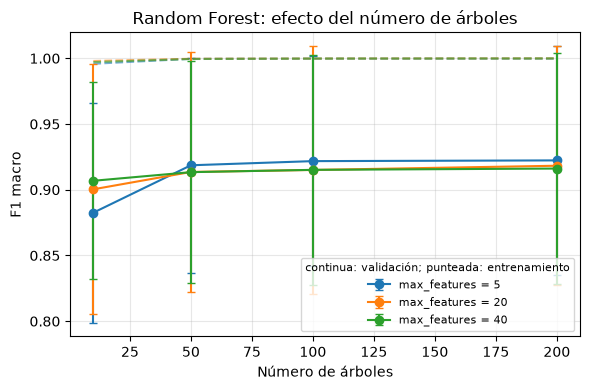

In [60]:
graficar(tabla_rf, "n_estimators", serie="max_features", titulo="Random Forest: efecto del número de árboles", etiqueta_x="Número de árboles")
plt.tight_layout(); plt.savefig("fig_random_forest.png", dpi=200); plt.show()

## 10. Red neuronal: perceptrón multicapa (MLP)

**Qué es:** capas de neuronas; cada neurona hace una suma ponderada de lo que recibe y le aplica una función no lineal (ReLU). La última capa entrega una probabilidad por actividad. Se entrena ajustando los pesos para reducir el error (clase 13).

**Por qué un MLP sobre las 561 características y no una red convolucional** [Interpretación]: [Fuente] Ronao y Cho (2016) usan una red convolucional sobre las señales crudas y obtienen 94,79 % a 95,75 %, sin superar con claridad a la SVM de Anguita et al. sobre las características calculadas. Como nuestra entrada son las 561 características, una red densa es la opción natural y la que pide la guía.

| Hiperparámetro | Qué controla | Malla |
| --- | --- | --- |
| Capas ocultas | Profundidad de la red | 1, 2, 3 |
| Neuronas por capa | Capacidad de cada capa | 16, 32, 64 |

Se fija activación ReLU, como en el laboratorio 4, hasta 500 épocas y semilla 0 para que el resultado sea reproducible.

In [61]:
mlp = Pipeline([("escalar", StandardScaler()),
                ("modelo", MLPClassifier(activation="relu", max_iter=500, random_state=0))])
malla_mlp = {"modelo__hidden_layer_sizes": [(n,) * capas for capas in [1, 2, 3] for n in [16, 32, 64]]}

buscar("Red neuronal (MLP)", mlp, malla_mlp)
tabla_mlp = tabla(busquedas["Red neuronal (MLP)"])
tabla_mlp["capas"] = tabla_mlp["hidden_layer_sizes"].apply(len)
tabla_mlp["neuronas"] = tabla_mlp["hidden_layer_sizes"].apply(lambda t: t[0])
tabla_mlp

Red neuronal (MLP): 9 combinaciones en 137 s
Mejores hiperparámetros: {'hidden_layer_sizes': (32,)}
F1 macro validación: 0.9348 ± 0.0741


,hidden_layer_sizes,f1_val,f1_val_2std,f1_ent,f1_ent_2std,acc_val,acc_val_2std,seg_ajuste,ranking,capas,neuronas
0,"(32,)",0.934761,0.074125,1.000000,0.000000,0.935278,0.069811,43.754823,1,1,32
1,"(16,)",0.931745,0.085555,1.000000,0.000000,0.933305,0.078267,48.428287,2,1,16
2,"(32, 32)",0.931051,0.088066,1.000000,0.000000,0.932187,0.081870,26.287899,3,2,32
3,"(64, 64)",0.927115,0.081921,1.000000,0.000000,0.928531,0.075452,24.227818,4,2,64
4,"(64,)",0.926995,0.090182,1.000000,0.000000,0.928031,0.083539,32.786074,5,1,64
5,"(16, 16, 16)",0.924392,0.090610,0.999667,0.001163,0.925326,0.084304,25.052398,6,3,16
6,"(16, 16)",0.923701,0.086288,0.999591,0.001231,0.924597,0.081300,37.751279,7,2,16
7,"(64, 64, 64)",0.923137,0.088957,1.000000,0.000000,0.925444,0.080496,16.596085,8,3,64
8,"(32, 32, 32)",0.922286,0.088804,1.000000,0.000000,0.923291,0.081977,21.682029,9,3,32


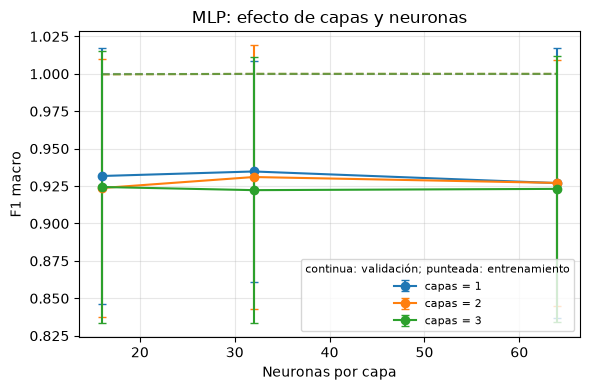

In [62]:
graficar(tabla_mlp, "neuronas", serie="capas", titulo="MLP: efecto de capas y neuronas", etiqueta_x="Neuronas por capa")
plt.tight_layout(); plt.savefig("fig_mlp.png", dpi=200); plt.show()

## 11. Máquina de vectores de soporte (SVC con núcleo RBF)

**Qué es:** busca la frontera que deja el mayor margen posible entre clases. El núcleo RBF (gaussiano) le permite trazar fronteras curvas midiendo la similitud entre ventanas (clase 16).

**Por qué núcleo RBF** [Fuente]: Anguita et al. (2013) usan una SVM con núcleo gaussiano sobre estas mismas 561 características y obtienen 96 % en la partición oficial. Es la referencia directa del proyecto. Ellos usan la estrategia uno contra todos; `SVC` de scikit-learn usa uno contra uno internamente. Ambas se vieron en la clase 17.

| Hiperparámetro | Qué controla | Malla |
| --- | --- | --- |
| `C` | Castigo por clasificar mal: C grande ajusta más los datos (riesgo de sobreajuste) | 0,1; 1; 10; 100 |
| `gamma` | Alcance de cada punto: gamma grande hace fronteras muy locales | 0,0001; 0,001; 0,01 |

Con 561 características estandarizadas, el valor por defecto de scikit-learn (`gamma="scale"`) queda alrededor de 1/561 ≈ 0,0018; la malla lo rodea.

In [63]:
svm = Pipeline([("escalar", StandardScaler()), ("modelo", SVC(kernel="rbf"))])
malla_svm = {"modelo__C": [0.1, 1, 10, 100], "modelo__gamma": [0.0001, 0.001, 0.01]}

buscar("SVM (RBF)", svm, malla_svm)
tabla_svm = tabla(busquedas["SVM (RBF)"])
tabla_svm

SVM (RBF): 12 combinaciones en 423 s
Mejores hiperparámetros: {'C': 100, 'gamma': 0.0001}
F1 macro validación: 0.9322 ± 0.0911


,C,gamma,f1_val,f1_val_2std,f1_ent,f1_ent_2std,acc_val,acc_val_2std,seg_ajuste,ranking
0,100.0,0.0001,0.932172,0.091062,0.992169,0.003903,0.933911,0.082336,7.068757,1
1,10.0,0.0010,0.929729,0.077406,0.996161,0.002450,0.930869,0.071053,5.645036,2
2,10.0,0.0001,0.929010,0.095993,0.982837,0.005380,0.930528,0.088216,7.544917,3
3,100.0,0.0010,0.927270,0.076680,1.000000,0.000000,0.928434,0.069988,7.414702,4
4,1.0,0.0010,0.926179,0.087643,0.984339,0.005187,0.927233,0.080634,9.041364,5
5,1.0,0.0001,0.908983,0.099893,0.949549,0.011237,0.910341,0.092215,13.778196,6
6,0.1,0.0010,0.888588,0.097686,0.938078,0.015643,0.890691,0.089511,32.473199,7
7,10.0,0.0100,0.844851,0.128124,1.000000,0.000000,0.846986,0.124706,52.447210,8
8,100.0,0.0100,0.844851,0.128124,1.000000,0.000000,0.846986,0.124706,42.548981,8
9,1.0,0.0100,0.840272,0.124836,0.999719,0.000301,0.842219,0.121204,39.774609,10


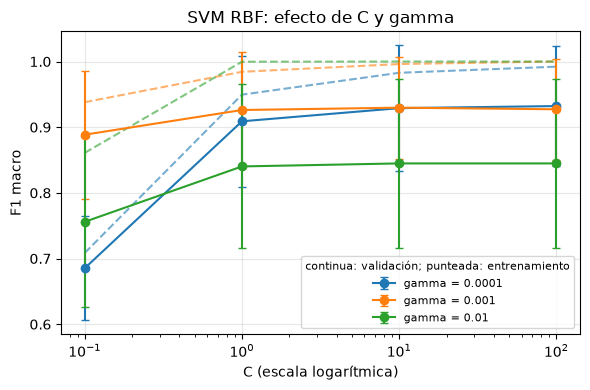

In [64]:
graficar(tabla_svm, "C", serie="gamma", titulo="SVM RBF: efecto de C y gamma", etiqueta_x="C (escala logarítmica)", log_x=True)
plt.tight_layout(); plt.savefig("fig_svm.png", dpi=200); plt.show()

## 12. Comparación de modelos en validación

Para cada modelo se toma su mejor configuración y se reportan entrenamiento y validación con su intervalo (media ± 2·desv. est. sobre las 5 particiones por voluntario). Los dos mejores modelos según el **F1 macro de validación** pasan a la etapa de reducción de dimensión. La elección no mira el test.

In [65]:
filas = []
for nombre, gs in busquedas.items():
    r, i = gs.cv_results_, gs.best_index_
    filas.append({
        "Modelo": nombre,
        "Mejores hiperparámetros": {k.replace("modelo__", ""): v for k, v in gs.best_params_.items()},
        "F1 entrenamiento": r["mean_train_f1"][i], "±2std ent.": 2 * r["std_train_f1"][i],
        "F1 validación": r["mean_test_f1"][i], "±2std val.": 2 * r["std_test_f1"][i],
        "Exactitud validación": r["mean_test_acc"][i], "±2std exac.": 2 * r["std_test_acc"][i],
        "Seg. por ajuste": r["mean_fit_time"][i],
    })
comparacion = pd.DataFrame(filas).sort_values("F1 validación", ascending=False).reset_index(drop=True)
comparacion.to_csv("resultados_validacion.csv", index=False)
comparacion.round(4)

,Modelo,Mejores hiperparámetros,F1 entrenamiento,±2std ent.,F1 validación,±2std val.,Exactitud validación,±2std exac.,Seg. por ajuste
0,LDA,{'shrinkage': 0.0001},0.9892,0.0051,0.9502,0.0591,0.9499,0.0573,1.3395
1,Red neuronal (MLP),"{'hidden_layer_sizes': (32,)}",1.0000,0.0000,0.9348,0.0741,0.9353,0.0698,43.7548
2,SVM (RBF),"{'C': 100, 'gamma': 0.0001}",0.9922,0.0039,0.9322,0.0911,0.9339,0.0823,7.0688
3,Random Forest,"{'max_features': 5, 'n_estimators': 200}",0.9997,0.0004,0.9223,0.0869,0.9249,0.0797,9.6730
4,KNN,"{'n_neighbors': 25, 'p': 1}",0.9721,0.0037,0.8924,0.0589,0.8953,0.0534,0.3497
5,Referencia,{'strategy': 'most_frequent'},0.0535,0.0012,0.0535,0.0049,0.1912,0.0207,0.0461


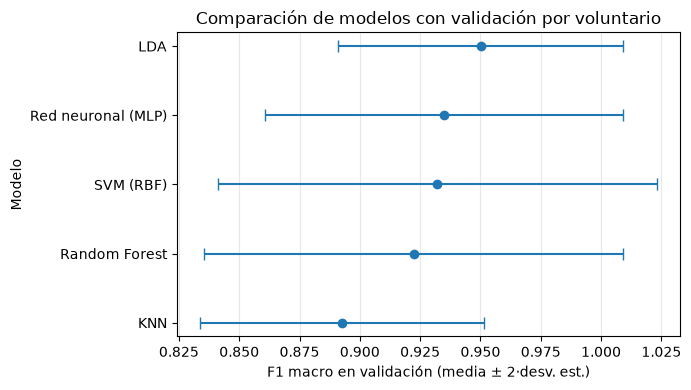

Modelos que pasan a reducción de dimensión: ['LDA', 'Red neuronal (MLP)']


In [66]:
# La referencia queda fuera de la gráfica (su F1 es casi 0); está en la tabla anterior
d = comparacion[comparacion["Modelo"] != "Referencia"].iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(d["F1 validación"], d["Modelo"], xerr=d["±2std val."], fmt="o", capsize=4)
ax.set_xlabel("F1 macro en validación (media ± 2·desv. est.)")
ax.set_ylabel("Modelo")
ax.set_title("Comparación de modelos con validación por voluntario")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig("fig_comparacion.png", dpi=200); plt.show()

mejores_dos = comparacion["Modelo"].iloc[:2].tolist()
print("Modelos que pasan a reducción de dimensión:", mejores_dos)

## 13. Evaluación final en la partición de prueba

Cada búsqueda ya reentrenó su mejor configuración con las 7 352 ventanas de entrenamiento (`refit`). Aquí se evalúan **una sola vez** sobre las 2 947 ventanas de los 9 voluntarios de prueba, que ningún modelo vio. Estos números no se usan para elegir nada: solo miden qué tan bien generalizan a personas nuevas.

In [67]:
X_test = partes["test"][nombres]
y_test = partes["test"]["actividad"]

filas = []
for nombre, gs in busquedas.items():
    pred = gs.best_estimator_.predict(X_test)
    filas.append({"Modelo": nombre,
                  "Exactitud prueba": accuracy_score(y_test, pred),
                  "F1 macro prueba": f1_score(y_test, pred, average="macro")})
prueba = pd.DataFrame(filas)
resumen = comparacion[["Modelo", "F1 entrenamiento", "F1 validación", "±2std val."]].merge(prueba, on="Modelo")
resumen.to_csv("resultados_prueba.csv", index=False)
resumen.round(4)

,Modelo,F1 entrenamiento,F1 validación,±2std val.,Exactitud prueba,F1 macro prueba
0,LDA,0.9892,0.9502,0.0591,0.9630,0.9633
1,Red neuronal (MLP),1.0000,0.9348,0.0741,0.9511,0.9516
2,SVM (RBF),0.9922,0.9322,0.0911,0.9562,0.9561
3,Random Forest,0.9997,0.9223,0.0869,0.9294,0.9260
4,KNN,0.9721,0.8924,0.0589,0.9043,0.8998
5,Referencia,0.0535,0.0535,0.0049,0.1822,0.0514


**Matriz de confusión del mejor modelo.** Las filas son la actividad real y las columnas la predicha. Normalizada por fila, la diagonal es la sensibilidad de cada actividad; sirve para revisar si se repite la confusión entre sentado y de pie que reportan Anguita et al. (2013).

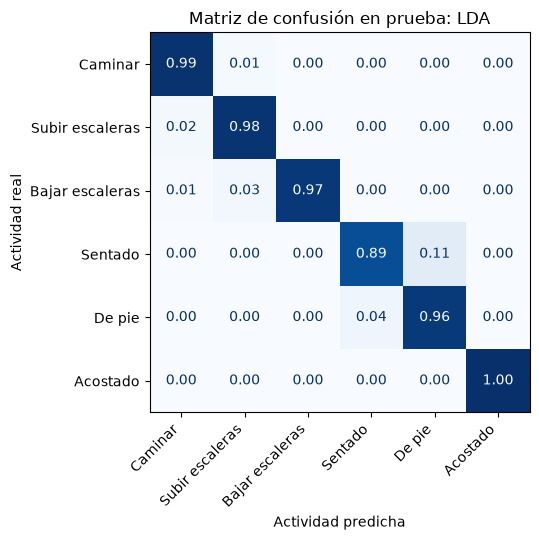

                 precision    recall  f1-score   support

        Caminar      0.972     0.988     0.980       496
Subir escaleras      0.962     0.977     0.969       471
Bajar escaleras      1.000     0.967     0.983       420
        Sentado      0.952     0.886     0.918       491
         De pie      0.903     0.959     0.930       532
       Acostado      1.000     1.000     1.000       537

       accuracy                          0.963      2947
      macro avg      0.965     0.963     0.963      2947
   weighted avg      0.964     0.963     0.963      2947



In [68]:
mejor = comparacion["Modelo"].iloc[0]
pred = busquedas[mejor].best_estimator_.predict(X_test)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, labels=orden, display_labels=[nombres_es[a] for a in orden],
    normalize="true", values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
ax.set_xlabel("Actividad predicha")
ax.set_ylabel("Actividad real")
ax.set_title(f"Matriz de confusión en prueba: {mejor}")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.savefig("fig_confusion.png", dpi=200); plt.show()

print(classification_report(y_test, pred, labels=orden,
                            target_names=[nombres_es[a] for a in orden], digits=3))

## 14. Comparación con el estado del arte y conclusiones

Resultados reportados en la misma partición oficial por voluntario (primer informe):

| Trabajo | Modelo | Entrada | Exactitud en prueba |
| --- | --- | --- | --- |
| Anguita et al. (2013) | SVM uno contra todos, núcleo gaussiano | 561 características | 96 % |
| Ronao y Cho (2016) | Red convolucional | Señales crudas (+ FFT) | 94,79 % (95,75 %) |
| Xu et al. (2019) | Ensamble en cascada | 561 características | 96,67 % (media) |
| Pang et al. (2022) | SDFL | 561 características | 96,27 % |

*Completar después de ejecutar, con los números de las secciones 12 y 13:*

- ¿Cuál fue el mejor modelo en validación y en prueba? ¿Coinciden?
- ¿Qué tan lejos queda de los trabajos de la tabla? Ronao y Cho no son directamente comparables, porque usan otra entrada.
- ¿Se repite la confusión entre sentado y de pie?
- ¿Qué modelos sobreajustan (F1 de entrenamiento mucho mayor que el de validación)?
- ¿Qué dos modelos pasan a la reducción de dimensión y por qué?